# **BREAST CANCER DETECTION USING DEEP LEARNING ALONG WITH THE USAGE OF ENSEMBLE ALGORITHMS BY USING LR-META CLASSIFIER WITH CROSS-VALIDATION STACKING MODEL**

In [5]:
# from google.colab import drive
# drive.mount('/content/drive')

##**1. IMPORTING NECESSARY DEPENDENCIES & LIBRARIES**

In [6]:
# Essential dependencies for 'Data Cleaning' purpose
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Essential for data consistency and restricting over-fitting
from sklearn.pipeline import Pipeline

# Fundamental libraries for 'Data Preprocessing' purpose
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder

# Important Libraries for 'Model training & building' purpose
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.layers import Dense, Input
from keras.models import Sequential
from keras.callbacks import EarlyStopping
import pickle

# Importing important standalone mathematical algorithms for building ml models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Important ensembling algorithms to ensemble different algorithms together
!pip install catboost
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier    # Stacking, Bagging, Boosting algorithms imported...
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Important modules for 'Model Evaluation' purpose
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, accuracy_score,
    recall_score, precision_score, f1_score
)

# Important libraries for 'Data Visualization' purpose
import tensorboard

# Import Warnings for skipping unnecessary warnings during testing
import warnings

# Displaying Tensorflow Version
tf.__version__

'2.21.0'

### Additional imports for ensemble evaluation and unsupervised learning
These are supplemental imports only. The original library-import section above is preserved as written.

In [7]:
# Additional imports only: keep the original imports above unchanged
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.base import clone


##**Step-1 : DATA COLLECTION & LOADING THE DATASET**



In [8]:
# Loading the dataset (CSV File)...
df = pd.read_csv('/content/breast_cancer_data.csv')

##**2. SETTING SEEDS & GLOBAL CONFIGURATIONS FOR DATASET**

In [9]:
# Setting seeds for reproducable results
np.random.seed(42)
tf.random.set_seed(42)


In [10]:
# Configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f'{x:.4f}')
np.set_printoptions(suppress=True)

##**3. Quick Exploration**

In [11]:
df.shape

(569, 33)

In [12]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,NaN
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,NaN
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,NaN
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,NaN
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,NaN


##**Step-2 : Data Cleaning**

In [13]:
# Dropping un-necessary columns
df = df.drop(columns= {"id", "Unnamed: 32"})

In [14]:
# Visualizing for the meta-data of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [15]:
# Checking for null rows & columns
df.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [16]:
# Checking for duplicate rows or values
df.duplicated().sum()

np.int64(0)

In [17]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [18]:
# Performing mathematical computations on the dataset
df.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000,569.0000
mean,14.1273,19.2896,91.9690,654.8891,0.0964,0.1043,0.0888,0.0489,0.1812,0.0628,0.4052,1.2169,2.8661,40.3371,0.0070,0.0255,0.0319,0.0118,0.0205,0.0038,16.2692,25.6772,107.2612,880.5831,0.1324,0.2543,0.2722,0.1146,0.2901,0.0839
std,3.5240,4.3010,24.2990,351.9141,0.0141,0.0528,0.0797,0.0388,0.0274,0.0071,0.2773,0.5516,2.0219,45.4910,0.0030,0.0179,0.0302,0.0062,0.0083,0.0026,4.8332,6.1463,33.6025,569.3570,0.0228,0.1573,0.2086,0.0657,0.0619,0.0181
min,6.9810,9.7100,43.7900,143.5000,0.0526,0.0194,0.0000,0.0000,0.1060,0.0500,0.1115,0.3602,0.7570,6.8020,0.0017,0.0023,0.0000,0.0000,0.0079,0.0009,7.9300,12.0200,50.4100,185.2000,0.0712,0.0273,0.0000,0.0000,0.1565,0.0550
25%,11.7000,16.1700,75.1700,420.3000,0.0864,0.0649,0.0296,0.0203,0.1619,0.0577,0.2324,0.8339,1.6060,17.8500,0.0052,0.0131,0.0151,0.0076,0.0152,0.0022,13.0100,21.0800,84.1100,515.3000,0.1166,0.1472,0.1145,0.0649,0.2504,0.0715
50%,13.3700,18.8400,86.2400,551.1000,0.0959,0.0926,0.0615,0.0335,0.1792,0.0615,0.3242,1.1080,2.2870,24.5300,0.0064,0.0204,0.0259,0.0109,0.0187,0.0032,14.9700,25.4100,97.6600,686.5000,0.1313,0.2119,0.2267,0.0999,0.2822,0.0800
75%,15.7800,21.8000,104.1000,782.7000,0.1053,0.1304,0.1307,0.0740,0.1957,0.0661,0.4789,1.4740,3.3570,45.1900,0.0081,0.0324,0.0420,0.0147,0.0235,0.0046,18.7900,29.7200,125.4000,1084.0000,0.1460,0.3391,0.3829,0.1614,0.3179,0.0921
max,28.1100,39.2800,188.5000,2501.0000,0.1634,0.3454,0.4268,0.2012,0.3040,0.0974,2.8730,4.8850,21.9800,542.2000,0.0311,0.1354,0.3960,0.0528,0.0790,0.0298,36.0400,49.5400,251.2000,4254.0000,0.2226,1.0580,1.2520,0.2910,0.6638,0.2075


##**Step-3 : DATA PREPROCESSING**

##**4. Feature Engineering**

##**5. Data Encoding for Categorical Variables**

In [19]:
df["diagnosis"] = df["diagnosis"].map({'B': 0, 'M': 1}).astype(int)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,1,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,1,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,1,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,1,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


In [20]:
class_names = ["benign", "malignant"]

##**6. Checking for Over-Sampling or Under-Sampling**

In [21]:
# Checking the distribution of the target variable for the purpose of over-sampling or under-sampling
df["diagnosis"].value_counts(normalize=True)*100

,proportion
diagnosis,
0,62.7417
1,37.2583


In [22]:
df[["radius_mean", "area_mean", "smoothness_mean"]].describe()

,radius_mean,area_mean,smoothness_mean
count,569.0000,569.0000,569.0000
mean,14.1273,654.8891,0.0964
std,3.5240,351.9141,0.0141
min,6.9810,143.5000,0.0526
25%,11.7000,420.3000,0.0864
50%,13.3700,551.1000,0.0959
75%,15.7800,782.7000,0.1053
max,28.1100,2501.0000,0.1634


##**7. Data Splitting (Train/ Test/ Val. Split)**

In [23]:
# Splitting the dataset into TRAIN, TEST & VALIDATION sets
X = df.drop(columns= {"diagnosis"})
y = df["diagnosis"]

In [24]:
# Distributing the data into training data(80%) and test data(20%)
X_train_full, X_test, y_train_full, y_test = train_test_split (
    X, y, test_size = 0.2, stratify = y, random_state=42
)

# Distributing the rest training data into final training data(64%) and validation data(16%)
X_train, X_val, y_train, y_val = train_test_split (
    X_train_full, y_train_full, test_size = 0.20, stratify = y_train_full, random_state=42
)

print("X_train : ", X_train.shape)
print("y_train : ", y_train.shape)
print("X_val : ", X_val.shape)
print("y_val : ", y_val.shape)

X_train :  (364, 30)
y_train :  (364,)
X_val :  (91, 30)
y_val :  (91,)


##**8. Scaling The Dataset**

In [25]:
# Scale the data through Standard Scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [26]:
X_train, X_test, X_val

(array([[-0.36140717, -0.32646221, -0.36151377, ..., -0.53145145,
         -0.19822483, -0.27362476],
        [-1.35598642, -1.51994945, -1.23025723, ..., -0.18175699,
          0.21098608,  2.37916223],
        [ 0.35849985,  0.0178577 ,  0.37952039, ...,  0.5540459 ,
         -0.10658686, -0.2154041 ],
        ...,
        [-0.52477069,  2.45834135, -0.59251146, ..., -1.72408411,
         -0.78281184, -0.95094434],
        [ 1.2417704 , -0.41952164,  1.26027413, ...,  1.85411482,
          1.41333936,  0.4567275 ],
        [-0.4721621 , -1.52925539, -0.53606315, ..., -1.320822  ,
         -0.98662731, -0.78665831]]),
 array([[-0.76289378, -1.99687905, -0.75585124, ..., -0.37616544,
          0.17622685,  0.07512277],
        [ 1.87584236,  0.96706392,  1.86879489, ...,  1.44332915,
          0.35002299, -0.31339927],
        [ 0.55508985, -0.77547398,  0.56367799, ...,  0.15830733,
          0.39268204,  0.32702801],
        ...,
        [ 0.10099465, -0.01471311,  0.08126515, ..., -

##**Step-4 : BUILD & TRAIN THE MODEL**

##**9. Model Building & Compiling**

In [27]:
X_train.shape[1]

30

In [28]:
# Building the structure of the model...

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    # Dense(2, activation='sigmoid')
])

In [29]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Compiling the model...

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate = 0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
    # metrics=['accuracy', 'precision']
)

##**10. Model Training**

In [31]:
# Setting early stopping for monotonic decreasing results purpose

earlystop_callback = EarlyStopping(
    monitor = 'val_loss',
    patience = 10,
    restore_best_weights = True
)

In [32]:
# Creating custom log displayer

class Print_metrics_per10(keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs):
    if(epoch + 1) % 10 == 0:
      print(f"Epoch {epoch + 1:3d}  "
            f"Acc {logs['accuracy']:.4f}  Loss {logs['loss']:.4f}  "
            f"Val_acc {logs['val_accuracy']:.4f}  Val_loss {logs['val_loss']:.4f}")
            # f"Val_acc {logs['val_accuracy']:.4f}  Val_preci {logs['precision']:.4f}  Val_loss {logs['val_loss']:.4f}")

In [33]:
# Training the model on the training set

history = model.fit(
    X_train, y_train,
    validation_data = (X_val, y_val),
    epochs = 80,
    batch_size = 32,
    callbacks = [earlystop_callback, Print_metrics_per10()],
    verbose = 0
)

Epoch  10  Acc 0.9560  Loss 0.1911  Val_acc 0.9670  Val_loss 0.1879
Epoch  20  Acc 0.9808  Loss 0.0826  Val_acc 0.9560  Val_loss 0.1013
Epoch  30  Acc 0.9918  Loss 0.0552  Val_acc 0.9670  Val_loss 0.0877
Epoch  40  Acc 0.9945  Loss 0.0421  Val_acc 0.9670  Val_loss 0.0871


In [34]:
# Training the model on the training set(Specifically for two outputs)

# history = model.fit(
#     X_train, y_train,
#     validation_split = 0.1,
#     epochs = 80,
#     batch_size = 32
# )

In [35]:
print("This model is trained for", len(history.history['loss']))

This model is trained for 48


##**11. Learning Curves**

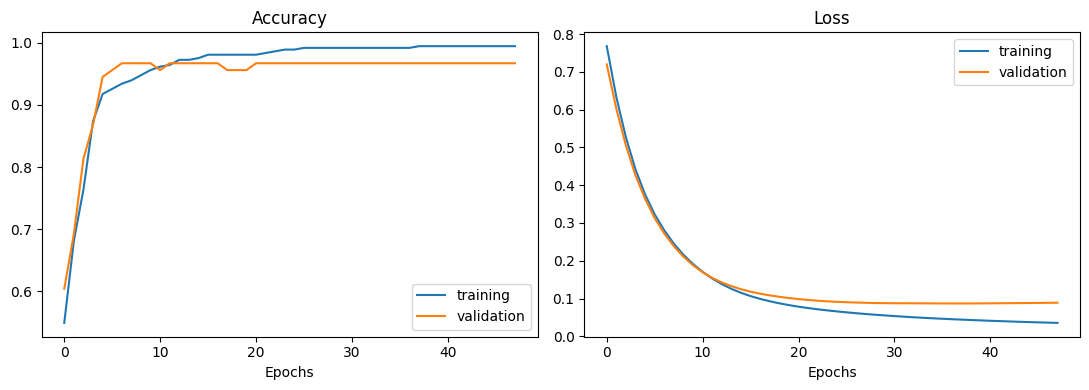

In [36]:
# Plotting curves for data analysis and visualization
hist = history.history

plt.figure(figsize=(11,4))

plt.subplot(1,2,1)
plt.plot(hist['accuracy'], label='training')
plt.plot(hist['val_accuracy'], label='validation')
plt.xlabel('Epochs')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(hist['loss'], label='training')
plt.plot(hist['val_loss'], label='validation')
plt.xlabel('Epochs')
plt.title('Loss')
plt.legend()

plt.tight_layout()
plt.show()

##**Step-5 : MODEL EVALUATION & TUNING**

##**12. Predicting Final Output**

In [37]:
# Evaluating the trained model on the test data...
# test_loss, test_acc, test_preci = model.evaluate(X_test, y_test)
test_loss, test_acc = model.evaluate(X_test, y_test)
print("Test_loss : ", round(test_loss, 3))
print("Test_accuracy : ", round(test_acc, 3))
# print("Test_precision : ", round(test_preci, 3))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9737 - loss: 0.0660
Test_loss :  0.066
Test_accuracy :  0.974


In [38]:
# Now predicting model's probability on the dataset given
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Top 5 probabilities: ", y_prob[:5].round(3))
print("Top 5 predictions: ", y_pred[:5])

Top 5 probabilities:  [0.    1.    0.066 0.425 0.354]
Top 5 predictions:  [0 1 0 0 0]


##**13. Classification Report(Precision, Recall, F1-score etc.)**

In [39]:
print(classification_report(y_test, y_pred, target_names = class_names))

              precision    recall  f1-score   support

      benign       0.96      1.00      0.98        72
   malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



##**14. Confusion Matrix**

In [40]:
confusion_matrix(y_test, y_pred)

array([[72,  0],
       [ 3, 39]])

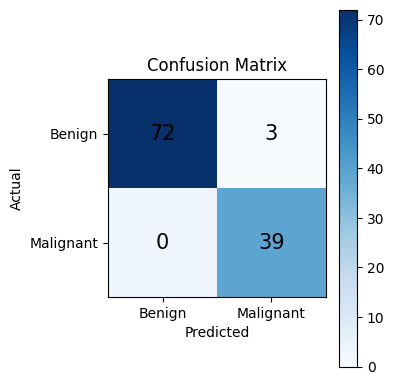

In [41]:
# Plotting the confusion matrix in terms of cmap for easier visualization
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4,4))
plt.imshow(cm, cmap = "Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ['Benign', 'Malignant'])
plt.yticks([0, 1], ['Benign', 'Malignant'])
for i in range(2):
  for j in range(2):
    plt.text(i, j, cm[i, j], ha='center', va='center', fontsize=15)
plt.colorbar()

plt.tight_layout()
plt.show()

##**15. Auc, Roc Curve, Roc-auc Score**

In [42]:
# Evaluation on the basis of roc-auc score & roc_curve
# roc = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)
print(auc.round(3))

0.998


---
## **Step-6 : ENSEMBLE ALGORITHMS & LR-META STACKING**
### **16. Preparing the Data**
The dataset contains **569 records and 30 input features**. The target is **benign = 0** or **malignant = 1**. We use 364 records for training, 91 for validation, and 114 for testing.

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from IPython.display import display

SEED = 42
N_FOLDS = 5
MODEL_NAMES = [
    "Logistic Regression", "Random Forest", "SVM", "KNN",
    "Gradient Boosting", "AdaBoost", "ANN", "LightGBM", "CatBoost"
]

# Keep the raw measurements so each training fold can fit its own scaler.
X_raw = df.drop(columns=["diagnosis"]).copy()
y_raw = df["diagnosis"].copy()

assert X_raw.shape == (569, 30), "Expected 569 records and 30 features."
assert set(y_raw.unique()) == {0, 1}, "Encode benign as 0 and malignant as 1."
assert np.isfinite(X_raw.to_numpy(dtype=float)).all(), "Check missing or infinite values."
assert not X_raw.duplicated().any(), "Review repeated measurements before splitting."

X_train_raw, X_test_raw, y_train_new, y_test_new = train_test_split(
    X_raw, y_raw, test_size=0.20, stratify=y_raw, random_state=SEED
)
X_train_raw, X_val_raw, y_train_new, y_val_new = train_test_split(
    X_train_raw, y_train_new, test_size=0.20,
    stratify=y_train_new, random_state=SEED
)

print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)
print("Test:", X_test_raw.shape)


### **17. Defining the Base Models**
Logistic Regression, SVM, and KNN use standardized measurements. Tree models use the original measurements. The ANN has two hidden layers, dropout, and early stopping.

In [ ]:
base_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=1
    ),
    "SVM": make_pipeline(
        StandardScaler(), SVC(kernel="rbf", probability=True, random_state=SEED)
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=7)
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=120, learning_rate=0.05, max_depth=2, random_state=SEED
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=120, learning_rate=0.05, random_state=SEED
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=150, learning_rate=0.05, num_leaves=15,
        reg_lambda=1.0, verbosity=-1, random_state=SEED, n_jobs=1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=150, learning_rate=0.05, depth=4,
        random_seed=SEED, verbose=False, allow_writing_files=False, thread_count=1
    )
}

def build_ann():
    tf.keras.utils.set_random_seed(SEED)
    network = keras.Sequential([
        keras.layers.Input(shape=(30,)),
        keras.layers.Dense(32, activation="relu",
                           kernel_regularizer=keras.regularizers.l2(0.0001)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, activation="relu",
                           kernel_regularizer=keras.regularizers.l2(0.0001)),
        keras.layers.Dropout(0.1),
        keras.layers.Dense(1, activation="sigmoid")
    ])
    network.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return network


### **18. Training & Probability Predictions**
These helpers train the nine models and collect their malignant-class probabilities. For the ANN, a small stratified part of the current training fold is used for early stopping. Its scaler is fitted only on the remaining optimization rows.

In [ ]:
def train_models(X_fit, y_fit):
    fitted_models = {}

    # Train the eight scikit-learn-compatible models.
    for name, estimator in base_models.items():
        fitted_models[name] = clone(estimator).fit(X_fit, y_fit)

    # Create the ANN's stopping set inside the current training data.
    X_ann, X_stop, y_ann, y_stop = train_test_split(
        X_fit, y_fit, test_size=0.15, stratify=y_fit, random_state=SEED
    )
    ann_scaler = StandardScaler()
    X_ann = ann_scaler.fit_transform(X_ann)
    X_stop = ann_scaler.transform(X_stop)

    ann = build_ann()
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True
    )
    ann_history = ann.fit(
        X_ann, y_ann, validation_data=(X_stop, y_stop),
        epochs=80, batch_size=32, callbacks=[early_stop], verbose=0
    )

    fitted_models["ANN"] = {"network": ann, "scaler": ann_scaler}
    return fitted_models, ann_history.history


def get_probabilities(fitted_models, X_input):
    probabilities = pd.DataFrame(index=X_input.index)

    # Keep the same column order during training and prediction.
    for name in MODEL_NAMES:
        fitted = fitted_models[name]
        if name == "ANN":
            scaled = fitted["scaler"].transform(X_input)
            probabilities[name] = np.asarray(
                fitted["network"](scaled, training=False)
            ).ravel()
        else:
            probabilities[name] = fitted.predict_proba(X_input)[:, 1]

    return probabilities


### **19. Five-Fold Predictions for Stacking**
Split the training records into five folds. In each round, train on four folds and predict the remaining fold. Each row therefore receives nine probabilities from models that did not train on that row. Logistic Regression learns from these probabilities.

The fold results below evaluate the base learners. The separate validation set evaluates the complete stack.

In [ ]:
folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# One row per training record and one column per base model.
oof_probabilities = pd.DataFrame(
    np.nan, index=X_train_raw.index, columns=MODEL_NAMES
)
fold_results = []

for fold_number, (fit_rows, holdout_rows) in enumerate(
    folds.split(X_train_raw, y_train_new), start=1
):
    X_fit = X_train_raw.iloc[fit_rows]
    y_fit = y_train_new.iloc[fit_rows]
    X_holdout = X_train_raw.iloc[holdout_rows]
    y_holdout = y_train_new.iloc[holdout_rows]

    fold_models, _ = train_models(X_fit, y_fit)
    fold_probabilities = get_probabilities(fold_models, X_holdout)
    oof_probabilities.iloc[holdout_rows] = fold_probabilities.to_numpy()

    for name in MODEL_NAMES:
        predictions = (fold_probabilities[name] >= 0.5).astype(int)
        fold_results.append({
            "Model": name,
            "Fold": fold_number,
            "Accuracy": accuracy_score(y_holdout, predictions),
            "Recall": recall_score(y_holdout, predictions, zero_division=0),
            "F1": f1_score(y_holdout, predictions, zero_division=0)
        })

    print("Completed fold", fold_number, "of", N_FOLDS)
    del fold_models

assert not oof_probabilities.isna().any().any()
fold_table = pd.DataFrame(fold_results)
display(fold_table.groupby("Model")[["Accuracy", "Recall", "F1"]].agg(["mean", "std"]).round(4))


### **20. Training the LR Meta-Classifier**
The meta-classifier receives nine probabilities instead of the original 30 measurements. Base models are then trained on the training partition to produce probabilities for validation and test records.

In [ ]:
meta_model = LogisticRegression(max_iter=2000, random_state=SEED)
meta_model.fit(oof_probabilities, y_train_new)

trained_models, ann_history = train_models(X_train_raw, y_train_new)
validation_probabilities = get_probabilities(trained_models, X_val_raw)

stack_val_probability = meta_model.predict_proba(validation_probabilities)[:, 1]
print("The base models and LR meta-classifier are ready.")


### **21. Comparing Validation Results**
Accuracy measures overall correctness. Recall measures the proportion of malignant cases detected. F1 balances precision and recall. ROC-AUC measures ranking performance across thresholds. Classification uses a fixed probability threshold of 0.5.

In [ ]:
def calculate_metrics(y_true, probability):
    prediction = (np.asarray(probability) >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probability)
    }

validation_results = []
for name in MODEL_NAMES:
    scores = calculate_metrics(y_val_new, validation_probabilities[name])
    validation_results.append({"Model": name, **scores})

validation_results.append({
    "Model": "LRMeta Stacking",
    **calculate_metrics(y_val_new, stack_val_probability)
})
validation_table = pd.DataFrame(validation_results).set_index("Model")
display(validation_table.round(4))


### **22. Learning Curves & Training–Validation Comparison**
Compare the ANN's training and stopping-set curves. Falling training loss with rising stopping-set loss can indicate overfitting. Also compare the complete stack's training and validation results; a small gap alone does not prove generalization.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ann_history["accuracy"], label="ANN training")
axes[0].plot(ann_history["val_accuracy"], label="ANN stopping set")
axes[0].set_title("ANN Accuracy")

axes[1].plot(ann_history["loss"], label="ANN training")
axes[1].plot(ann_history["val_loss"], label="ANN stopping set")
axes[1].set_title("ANN Loss")

for ax in axes:
    ax.set_xlabel("Epoch (zero-based)")
    ax.legend()
plt.tight_layout()
plt.show()

train_probabilities = get_probabilities(trained_models, X_train_raw)
stack_train_probability = meta_model.predict_proba(train_probabilities)[:, 1]

comparison = pd.DataFrame({
    "Training (in-sample)": calculate_metrics(y_train_new, stack_train_probability),
    "Validation": calculate_metrics(y_val_new, stack_val_probability)
}).T
display(comparison.round(4))
print("ANN epochs completed:", len(ann_history["loss"]))


---
## **Step-7 : UNSUPERVISED LEARNING**
### **23. K-Means Clustering**
K-Means finds two groups using measurements without diagnosis labels. Cluster numbers do not mean benign or malignant. Silhouette describes cluster separation; ARI compares the clusters with known labels afterward.

In [ ]:
cluster_scaler = StandardScaler()
X_cluster_train = cluster_scaler.fit_transform(X_train_raw)
X_cluster_val = cluster_scaler.transform(X_val_raw)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=SEED)
train_clusters = kmeans.fit_predict(X_cluster_train)
val_clusters = kmeans.predict(X_cluster_val)

if len(np.unique(train_clusters)) > 1:
    print("Training silhouette:", round(silhouette_score(X_cluster_train, train_clusters), 4))

print("Validation ARI:", round(adjusted_rand_score(y_val_new, val_clusters), 4))
print("Validation NMI:", round(normalized_mutual_info_score(y_val_new, val_clusters), 4))

display(pd.crosstab(
    pd.Series(y_val_new.to_numpy(), name="Known diagnosis"),
    pd.Series(val_clusters, name="Cluster")
))


### **24. PCA Visualization**
PCA reduces 30 measurements to two plotting axes. It is fitted on training measurements only. The two plots show the same records, colored first by clusters and then by known diagnosis. Overlap in a two-dimensional plot does not by itself identify noisy data.

In [ ]:
pca = PCA(n_components=2, random_state=SEED)
points = pca.fit_transform(X_cluster_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(points[:, 0], points[:, 1], c=train_clusters, cmap="viridis", alpha=0.7)
axes[0].set_title("K-Means Clusters")
axes[1].scatter(points[:, 0], points[:, 1], c=y_train_new, cmap="viridis", alpha=0.7)
axes[1].set_title("Known Diagnoses: 0 = Benign, 1 = Malignant")

for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print("Variance retained by two components:", round(pca.explained_variance_ratio_.sum(), 4))


### **25. Small Measurement Changes**
This validation-only check adds small artificial changes to measurements and counts prediction changes. It measures sensitivity to these specific perturbations, not the amount of noise or label error in the real dataset.

In [ ]:
rng = np.random.default_rng(SEED)
feature_std = X_train_raw.std(ddof=0).to_numpy()
original_predictions = (stack_val_probability >= 0.5).astype(int)
noise_results = []

for noise_level in [0.0, 0.01, 0.03]:
    changes = rng.normal(
        0, noise_level * feature_std, size=X_val_raw.shape
    )
    # These cell measurements are non-negative.
    changed_values = np.maximum(X_val_raw.to_numpy() + changes, 0)
    changed_data = pd.DataFrame(
        changed_values, columns=X_val_raw.columns, index=X_val_raw.index
    )
    changed_probabilities = get_probabilities(trained_models, changed_data)
    probability = meta_model.predict_proba(changed_probabilities)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    noise_results.append({
        "Noise fraction of training standard deviation": noise_level,
        "Validation Accuracy": accuracy_score(y_val_new, prediction),
        "Validation Recall": recall_score(y_val_new, prediction, zero_division=0),
        "Changed predictions": int(np.sum(prediction != original_predictions))
    })

display(pd.DataFrame(noise_results).round(4))


---
## **Step-8 : FINAL STACKING EVALUATION**
### **26. Test Metrics, Confusion Matrix & ROC Curve**
Evaluate the fixed model and threshold on the 114 test records. Keep validation and test metrics separately labeled. This partition is also used in the earlier ANN evaluation; independent external data is needed to establish performance beyond this dataset. Avoid changing model settings based on test results.

In [ ]:
test_probabilities = get_probabilities(trained_models, X_test_raw)
stack_test_probability = meta_model.predict_proba(test_probabilities)[:, 1]
stack_test_prediction = (stack_test_probability >= 0.5).astype(int)

test_scores = calculate_metrics(y_test_new, stack_test_probability)
display(pd.Series(test_scores, name="LRMeta Test Results").round(4))

print(classification_report(
    y_test_new, stack_test_prediction,
    labels=[0, 1], target_names=["benign", "malignant"], zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test_new, stack_test_prediction, labels=[0, 1],
    display_labels=["benign", "malignant"], ax=axes[0], colorbar=False
)
axes[0].set_title("LRMeta Test Confusion Matrix")
RocCurveDisplay.from_predictions(y_test_new, stack_test_probability, ax=axes[1])
axes[1].set_title("LRMeta Test ROC Curve")
plt.tight_layout()
plt.show()

final_results = comparison.copy()
final_results.loc["Test"] = test_scores
display(final_results.round(4))


---
## **Step-9 : SAVING THE MODELS**
### **27. Optional Model Export**
Set `SAVE_MODELS = True` after training to save the base models, ANN, ANN scaler, and meta-classifier. The feature names, model order, and classification threshold are saved with them. Predict in that same order when integrating the ensemble into an application.

In [ ]:
import json
import joblib
from pathlib import Path

SAVE_MODELS = False

if SAVE_MODELS:
    output_folder = Path("model_exports")
    # Use a new folder for each completed run.
    output_folder.mkdir(exist_ok=False)

    traditional_models = {
        name: trained_models[name] for name in MODEL_NAMES if name != "ANN"
    }
    joblib.dump(traditional_models, output_folder / "base_models.joblib")
    joblib.dump(trained_models["ANN"]["scaler"], output_folder / "ann_scaler.joblib")
    trained_models["ANN"]["network"].save(output_folder / "ann.keras")
    joblib.dump(meta_model, output_folder / "lr_meta.joblib")

    metadata = {
        "feature_order": list(X_train_raw.columns),
        "model_order": MODEL_NAMES,
        "class_mapping": {"benign": 0, "malignant": 1},
        "threshold": 0.5,
        "validation_metrics": calculate_metrics(y_val_new, stack_val_probability),
        "test_metrics": test_scores
    }
    with open(output_folder / "metadata.json", "w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2)

    print("Models saved in:", output_folder.resolve())
else:
    print("Set SAVE_MODELS = True when you want to export the trained models.")
